# Part 1 - Price Cut

**Result:** the cut clearly raised membership. Revenue per customer in percentage terms did not measurably change, because the extra members roughly offset the lower price (§5a). The dollar DiD looks significant, but its placebos and pre-cut climb point to revenue growing over time rather than to the cut.

The Westeros adjustment moves the DiD by at most \$0.009, 0.005 log points and 0.08 pp, which is small next to every CI and band. This matches EDA suggestion §7.

---

## *Prompt used for AI
1. Run a DiD event study using Winter 2019 as the reference. Use historical-gap bands and add model-based confidence interval as diagnostic.
2. Run placebo tests using only pre-cut data. Each fake cut should have at least 4 pre-cut and 4 post-cut seasons.
3. Run a standard DiD to estimate the average treatment effect per customer per season, using all pre- and post-cut periods.
4. Include region and time fixed effects, and weight by customer count. I also want to add a Westeros winter adjustment because it shows 0 impression but test the results without it too.
5. Make the code modular, write the helper functions into the `utils.py`, so I can easily run everything on three metrics:
   - Revenue per customer
   - Log revenue per customer (log after aggregation)
   - Membership percentage

Have some plots functions to show band and gap cleanly. Also mark the price cut time on the plots.

In [125]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import utils as u

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
u.apply_style()

panel = u.load_panel('data/customer_panel.csv')
cells = u.build_cells(panel)
print(f"{len(panel):,} customer-season rows -> {len(cells)} cells "
      f"({cells['region_name'].nunique()} regions x {cells['t'].nunique()} seasons)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
6,121,068 customer-season rows -> 72 cells (6 regions x 12 seasons)


In [126]:
assert cells.groupby('region_name')['n'].nunique().eq(1).all(), 'a region has a different customer count in some season'
assert cells['treated'].eq(cells['region_name'].ne(u.CONTROL).astype(int)).all(), 'treated should be 0 for panem and 1 elsewhere'

periods = sorted(cells['t'].unique())

ev_terms = []
for k in periods:
    if k != u.REF_T:
        cells[f'ev_{k}'] = cells['treated'] * cells['t'].eq(k).astype(int)
        ev_terms.append(f'ev_{k}')

# Each cut region has exactly one 1 per event dummy; panem has none
ev_sums = cells.groupby('region_name')[ev_terms].sum()
is_cut = ev_sums.index != u.CONTROL
assert ev_sums[is_cut].eq(1).all().all(), 'a cut region does not have exactly one 1 per event dummy'
assert ev_sums[~is_cut].eq(0).all().all(), 'panem has a nonzero event dummy'

In [127]:
# One region, all seasons: the three metrics and the flags used in the regressions
cells.loc[cells['region_name'].eq('westeros'),
          ['region_name', 't', 'n', 'members', 'revenue', 'revenue_pc', 'log_revenue_pc', 'member_pct',
           'treated', 'post', 'treated_post', 'westeros_winter']].round(3)

,region_name,t,n,members,revenue,revenue_pc,log_revenue_pc,member_pct,treated,post,treated_post,westeros_winter
60,westeros,0,101594,2448,29256,0.288,-1.245,2.410,1,0,0,1
61,westeros,1,101594,8614,111126,1.094,0.090,8.479,1,0,0,0
62,westeros,2,101594,10065,121729,1.198,0.181,9.907,1,0,0,0
63,westeros,3,101594,11130,134739,1.326,0.282,10.955,1,0,0,0
64,westeros,4,101594,12435,151472,1.491,0.399,12.240,1,0,0,1
65,westeros,5,101594,9839,115858,1.140,0.131,9.685,1,0,0,0
66,westeros,6,101594,19423,251610,2.477,0.907,19.118,1,0,0,0
67,westeros,7,101594,18732,224184,2.207,0.791,18.438,1,0,0,0
68,westeros,8,101594,23506,292337,2.878,1.057,23.137,1,0,0,1
69,westeros,9,101594,25454,229855,2.262,0.816,25.055,1,1,1,0


## Regression terms shared by all metrics

**Event study.** `ev_k` = 1 for a cut region in season *k*. There is one dummy for every season except winter 2019, which is the reference.

$$y_{rt} = \alpha_r + \lambda_t + \sum_{k \neq \text{Win 2019}} \beta_k \,\text{ev}_{k,rt} \;+\; \gamma\,\text{westeros\_winter}_{rt} + \varepsilon_{rt}$$

**Standard DiD.** `treated_post` = 1 for a cut region from spring 2019 onwards. It was already built in `build_cells`.

$$y_{rt} = \alpha_r + \lambda_t + \delta\,\text{treated\_post}_{rt} \;+\; \gamma\,\text{westeros\_winter}_{rt} + \varepsilon_{rt}$$

Both are WLS on the 72 cells, weighted by the region's customer count. The $\gamma$ term is included "with the Westeros adjustment" and dropped "without".

**Placebo dates.** Keep only the nine pre-cut seasons (winter 2017 – winter 2019). A fake cut at season *k* needs at least 3 seasons before *k*, and at least 3 from *k* through winter 2019.

In [128]:
pre_cells = cells[cells['t'] < u.CUT_T].copy()
pre_periods = sorted(pre_cells['t'].unique())
fake_cuts = [k for k in pre_periods
             if sum(p < k for p in pre_periods) >= 3 and sum(p >= k for p in pre_periods) >= 3]

# Results are stored per metric, then per Westeros setting (True = with the adjustment)
points, bands, placebos, dids = {}, {}, {}, {}

pd.DataFrame({'fake cut': [u.period_label(k) for k in fake_cuts],
              'seasons before': [sum(p < k for p in pre_periods) for k in fake_cuts],
              'seasons from the fake cut to Win 2019': [sum(p >= k for p in pre_periods) for k in fake_cuts]})

,fake cut,seasons before,seasons from the fake cut to Win 2019
0,Fall 2017,3,6
1,Win 2018,4,5
2,Spr 2018,5,4
3,Sum 2018,6,3


---

Each metric below runs the same steps:

1. **Event-study regression**, with and without the Westeros adjustment.
2. **Historical band.**
3. **Event-study plot.**
4. **Standard DiD.**
5. **Placebo vs real plot.**

**How the band works.** The nine pre-cut event-study points, including winter 2019's 0, show how much the gap moves from season to season with no price change, and that includes panem's own shocks. The band is the 95% prediction interval for one more season from that history: pre-cut mean $\pm\, t_8 \cdot sd \cdot \sqrt{1 + 1/9}$. It is centred on the pre-cut average (dotted line), not on winter 2019, because the reference season is itself one noisy draw. For the DiD, the post-cut average gap minus the pre-cut average gap is compared with $\pm\, t_8 \cdot sd \cdot \sqrt{1/3 + 1/9}$.

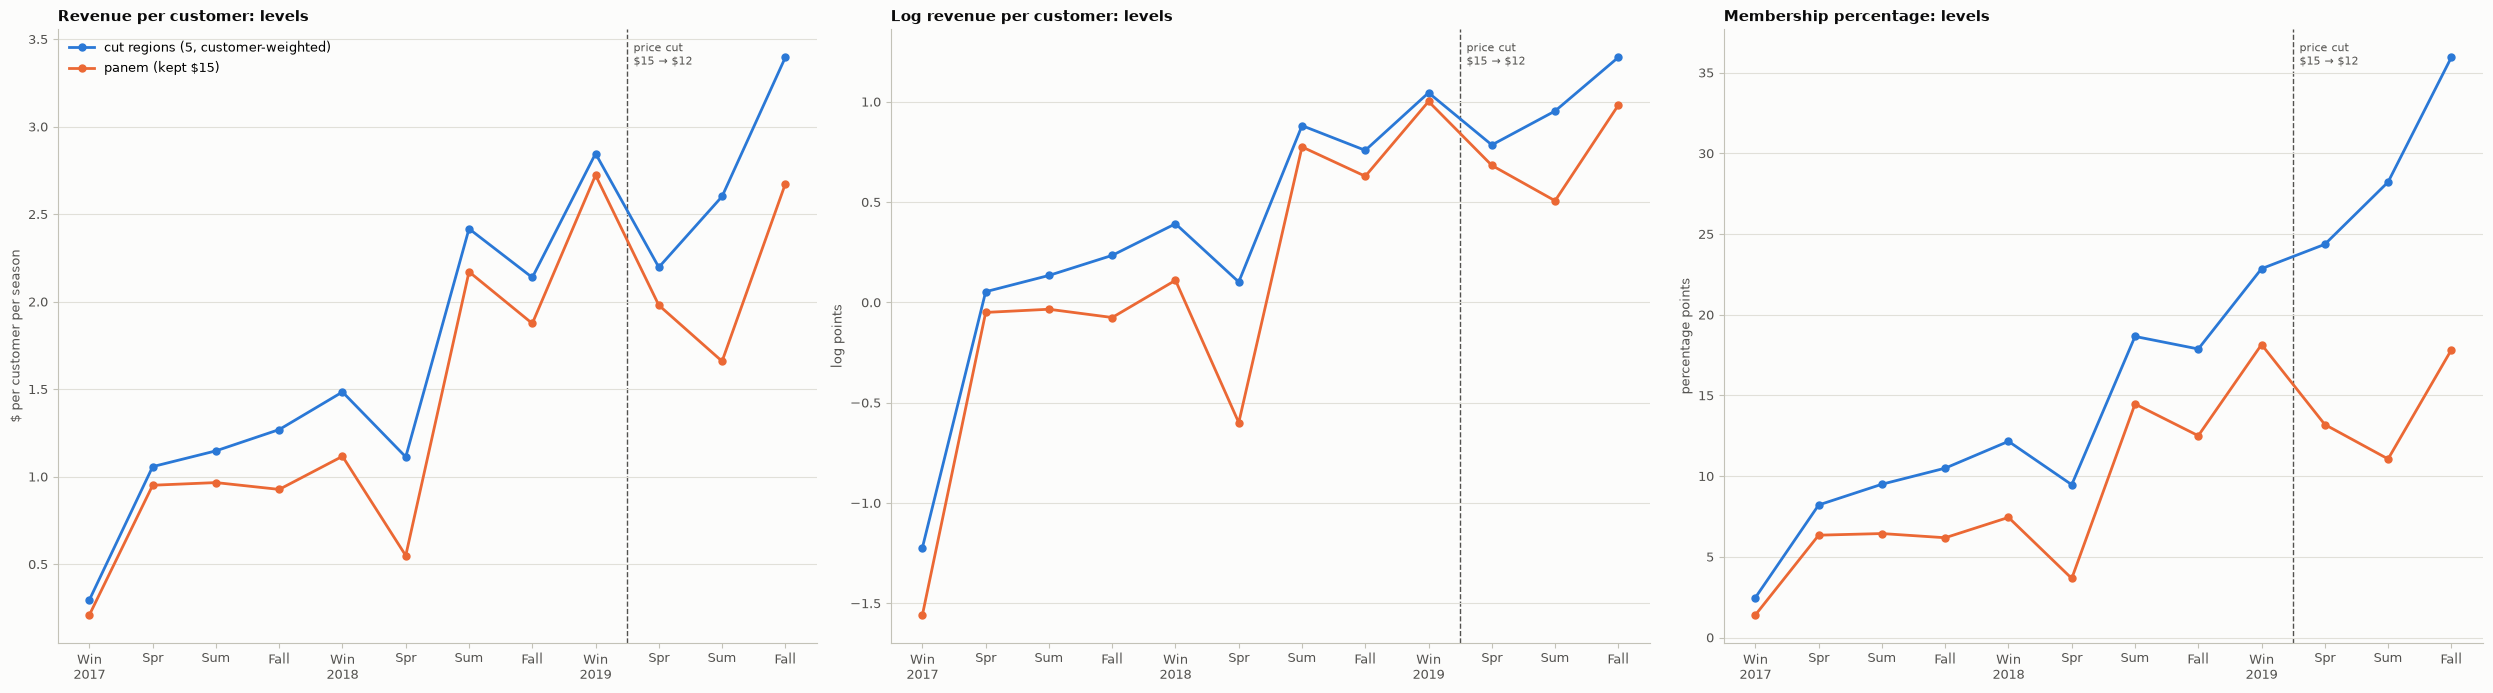

In [129]:
# Levles for all 3 metrics
fig, axes = plt.subplots(1, 3, figsize=(25, 7))
for ax, y in zip(axes, ['revenue_pc', 'log_revenue_pc', 'member_pct']):
    u.plot_levels(cells, y, ax=ax)
for ax in axes[1:]:
    ax.get_legend().remove()
plt.tight_layout()
plt.show()

## 1. Revenue per customer (`revenue_pc`, \$ per customer per season)

### 1.1 Event-study

This fits the model with and without the Westeros adjustment and turns the coefficients into points relative to winter 2019.

cells: 72 | parameters: 29 | westeros_winter: -0.073
largest |residual| in panem: 6.7e-15


,with Westeros adj.,without
n_pre,9.000,9.000
n_post,3.000,3.000
sd,0.151,0.154
t_crit,2.306,2.306
center,0.116,0.130
half_width,0.367,0.374
post_avg_gap,0.367,0.374
half_width_avg,0.232,0.236


,season,estimate,ci_low,ci_high,vs_band
9,Spr 2019,0.073,0.039,0.107,inside
10,Sum 2019,0.798,0.740,0.855,above
11,Fall 2019,0.579,0.534,0.623,above


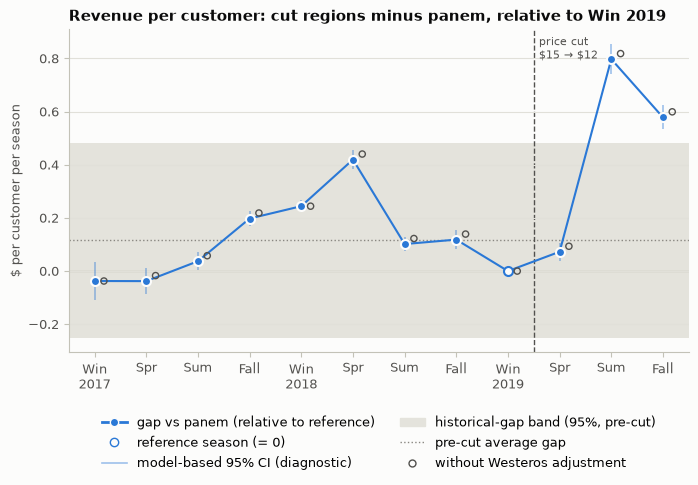

In [130]:
y = 'revenue_pc'
fit_es = {adj: u.fit_wls(cells, y, ev_terms, westeros_adj=adj) for adj in (True, False)}
points[y] = {adj: u.event_points(fit_es[adj], periods) for adj in (True, False)}

fit = fit_es[True]
print(f"cells: {int(fit.nobs)} | parameters: {len(fit.params)} | westeros_winter: {fit.params['westeros_winter']:+.3f}")
print(f"largest |residual| in panem: {fit.resid[cells['region_name'].eq(u.CONTROL)].abs().max():.1e}")

bands[y] = {adj: u.historical_band(points[y][adj]) for adj in (True, False)}
for adj in (True, False):
    p, b = points[y][adj], bands[y][adj]
    dev = p['estimate'] - b['center']
    p['vs_band'] = np.select([dev > b['half_width'], dev < -b['half_width']], ['above', 'below'], 'inside')

display(pd.DataFrame({'with Westeros adj.': bands[y][True], 'without': bands[y][False]}).round(3))
display(points[y][True].loc[lambda d: d['post'], ['season', 'estimate', 'ci_low', 'ci_high', 'vs_band']].round(3))

y = 'revenue_pc'
u.plot_event_study(points[y][True], bands[y][True], y, compare=points[y][False])
plt.show()

### 1.2 Standard DiD: average effect per customer per season

In [131]:
y = 'revenue_pc'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan),
                 'post − pre avg gap (event study)': bands[y][adj]['post_avg_gap'],
                 'historical band (avg) ±': bands[y][adj]['half_width_avg']}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.009


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef,post − pre avg gap (event study),historical band (avg) ±
westeros_adj,,,,,,,,
True,0.365,0.152,0.067,0.663,0.016,-0.097,0.367,0.232
False,0.374,0.151,0.078,0.670,0.013,NaN,0.374,0.236


### 1.3 Placebos vs the real cut

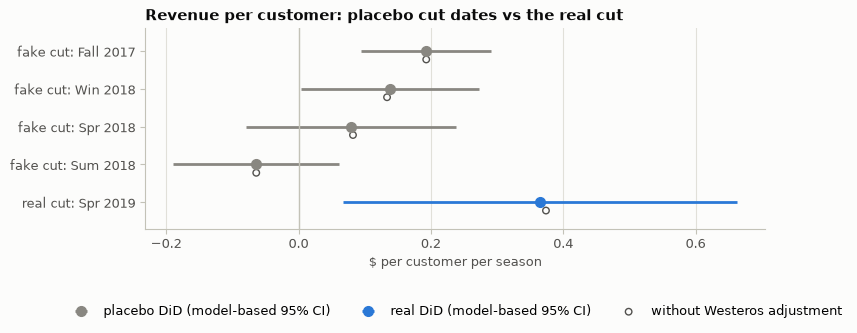

In [132]:
y = 'revenue_pc'

y = 'revenue_pc'
rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: revenue per customer (\$)**

* **Event study.** Summer and fall 2019 are above the band (+0.80 and +0.58, against 0.12 ± 0.37). Spring 2019 (+0.07) is inside. The pre-cut points already climb, from ≈ 0 in early 2017 to +0.1–0.4 in 2018.
* **Placebos.** +0.14 (its model CI just excludes 0) and +0.08. The dollar gap was already widening before the cut.
* **DiD.** +\$0.365 per customer per season, model CI [+0.07, +0.66]. The post − pre gap is +0.367, outside the ±0.232 band. Without the Westeros adjustment it is +\$0.374.
* **Caution.** Revenue per customer roughly triples over the window, so a steady *percentage* gap becomes a growing *dollar* gap.

## 2. Log revenue per customer (`log_revenue_pc`, log points)

### 2.1 Event-study

cells: 72 | parameters: 29 | westeros_winter: -0.051
largest |residual| in panem: 3.6e-15


,with Westeros adj.,without
n_pre,9.000,9.000
n_post,3.000,3.000
sd,0.200,0.200
t_crit,2.306,2.306
center,0.189,0.199
half_width,0.486,0.487
post_avg_gap,0.016,0.021
half_width_avg,0.307,0.308


,season,estimate,ci_low,ci_high,vs_band
9,Spr 2019,0.044,0.013,0.075,inside
10,Sum 2019,0.389,0.359,0.420,inside
11,Fall 2019,0.180,0.141,0.220,inside


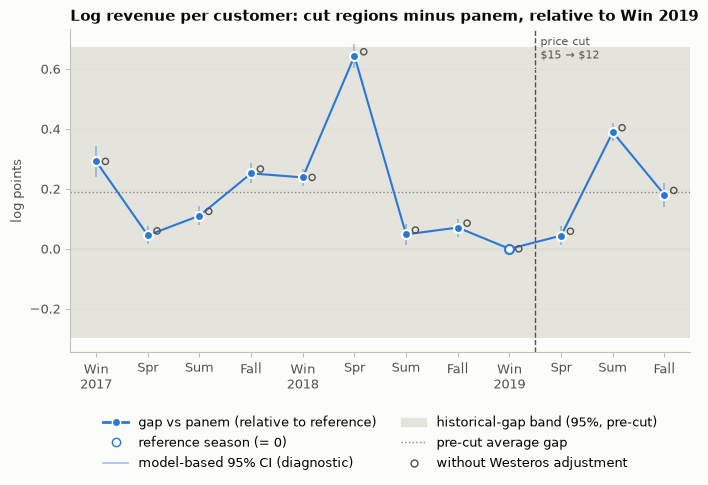

In [133]:
y = 'log_revenue_pc'
fit_es = {adj: u.fit_wls(cells, y, ev_terms, westeros_adj=adj) for adj in (True, False)}
points[y] = {adj: u.event_points(fit_es[adj], periods) for adj in (True, False)}

fit = fit_es[True]
print(f"cells: {int(fit.nobs)} | parameters: {len(fit.params)} | westeros_winter: {fit.params['westeros_winter']:+.3f}")
print(f"largest |residual| in panem: {fit.resid[cells['region_name'].eq(u.CONTROL)].abs().max():.1e}")
points[y][True].round(3)

bands[y] = {adj: u.historical_band(points[y][adj]) for adj in (True, False)}
for adj in (True, False):
    p, b = points[y][adj], bands[y][adj]
    dev = p['estimate'] - b['center']
    p['vs_band'] = np.select([dev > b['half_width'], dev < -b['half_width']], ['above', 'below'], 'inside')

display(pd.DataFrame({'with Westeros adj.': bands[y][True], 'without': bands[y][False]}).round(3))
display(points[y][True].loc[lambda d: d['post'], ['season', 'estimate', 'ci_low', 'ci_high', 'vs_band']].round(3))

y = 'log_revenue_pc'
u.plot_event_study(points[y][True], bands[y][True], y, compare=points[y][False])
plt.show()

### 2.2 Standard DiD: average effect per customer per season

In [134]:
y = 'log_revenue_pc'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan),
                 'post − pre avg gap (event study)': bands[y][adj]['post_avg_gap'],
                 'historical band (avg) ±': bands[y][adj]['half_width_avg']}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.005


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef,post − pre avg gap (event study),historical band (avg) ±
westeros_adj,,,,,,,,
True,0.015,0.087,-0.156,0.186,0.862,-0.057,0.016,0.307
False,0.021,0.086,-0.147,0.189,0.810,NaN,0.021,0.308


### 2.3 Placebos vs the real cut

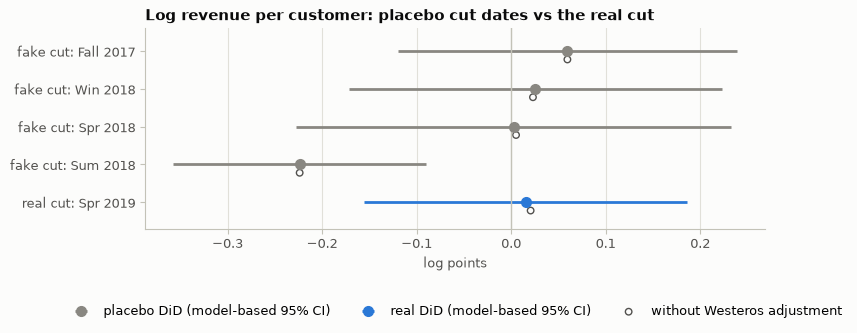

In [135]:
y = 'log_revenue_pc'

rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)
placebos[y].round(3)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: log revenue per customer**

* **Event study.** All three post-cut seasons are inside the band (0.19 ± 0.49). Summer 2019 (+0.39) is the highest post-cut point, but spring 2018 (+0.64) was higher, with no price change.
* **Placebos.** +0.026 and +0.003, the same size as the real estimate.
* **DiD.** +0.015 log points (≈ +1.5%), model CI [−0.16, +0.19]. The post − pre gap is +0.016, well inside the ±0.307 band. Without the Westeros adjustment it is +0.021.
* **Takeaway.** There is no detectable change in revenue per customer in percentage terms.

## 3. Membership percentage (`member_pct`, percentage points)

### 3.1 Event-study

cells: 72 | parameters: 29 | westeros_winter: -0.663
largest |residual| in panem: 5.7e-14


,with Westeros adj.,without
n_pre,9.000,9.000
n_post,3.000,3.000
sd,1.573,1.588
t_crit,2.306,2.306
center,-0.928,-0.802
half_width,3.823,3.860
post_avg_gap,11.522,11.585
half_width_avg,2.418,2.442


,season,estimate,ci_low,ci_high,vs_band
9,Spr 2019,6.276,5.800,6.751,above
10,Sum 2019,12.270,11.476,13.064,above
11,Fall 2019,13.237,12.554,13.921,above


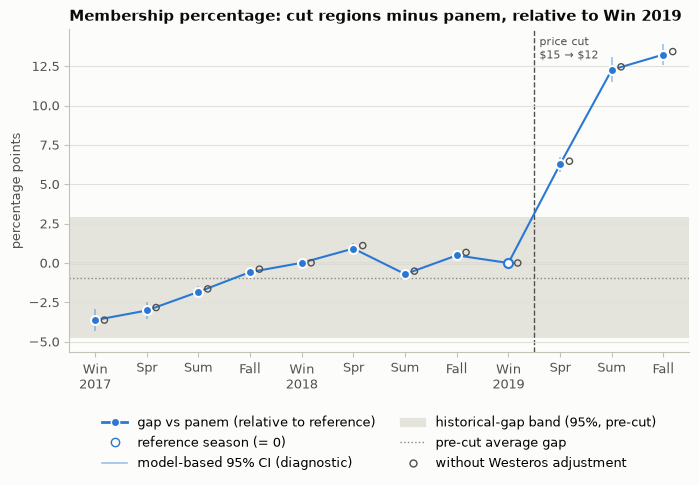

In [136]:
y = 'member_pct'

fit_es = {adj: u.fit_wls(cells, y, ev_terms, westeros_adj=adj) for adj in (True, False)}
points[y] = {adj: u.event_points(fit_es[adj], periods) for adj in (True, False)}

fit = fit_es[True]
print(f"cells: {int(fit.nobs)} | parameters: {len(fit.params)} | westeros_winter: {fit.params['westeros_winter']:+.3f}")
print(f"largest |residual| in panem: {fit.resid[cells['region_name'].eq(u.CONTROL)].abs().max():.1e}")
points[y][True].round(3)

bands[y] = {adj: u.historical_band(points[y][adj]) for adj in (True, False)}
for adj in (True, False):
    p, b = points[y][adj], bands[y][adj]
    dev = p['estimate'] - b['center']
    p['vs_band'] = np.select([dev > b['half_width'], dev < -b['half_width']], ['above', 'below'], 'inside')

display(pd.DataFrame({'with Westeros adj.': bands[y][True], 'without': bands[y][False]}).round(3))
display(points[y][True].loc[lambda d: d['post'], ['season', 'estimate', 'ci_low', 'ci_high', 'vs_band']].round(3))

u.plot_event_study(points[y][True], bands[y][True], y, compare=points[y][False])
plt.show()

### 3.2 Standard DiD: average effect per customer per season

In [137]:
y = 'member_pct'
rows = {}
for adj in (True, False):
    fit = u.fit_wls(cells, y, ['treated_post'], westeros_adj=adj)
    rows[adj] = {**u.coef_table(fit, ['treated_post']).iloc[0],
                 'westeros_winter_coef': fit.params.get('westeros_winter', np.nan),
                 'post − pre avg gap (event study)': bands[y][adj]['post_avg_gap'],
                 'historical band (avg) ±': bands[y][adj]['half_width_avg']}
dids[y] = pd.DataFrame(rows).T.rename_axis('westeros_adj')

print(f"Westeros adjustment changes the DiD by {dids[y].loc[True, 'estimate'] - dids[y].loc[False, 'estimate']:+.3f}")
dids[y].round(3)

Westeros adjustment changes the DiD by -0.076


,estimate,se,ci_low,ci_high,p_value,westeros_winter_coef,post − pre avg gap (event study),historical band (avg) ±
westeros_adj,,,,,,,,
True,11.509,1.549,8.474,14.544,0.0,-0.803,11.522,2.418
False,11.585,1.539,8.568,14.602,0.0,NaN,11.585,2.442


### 3.3 Placebos vs the real cut

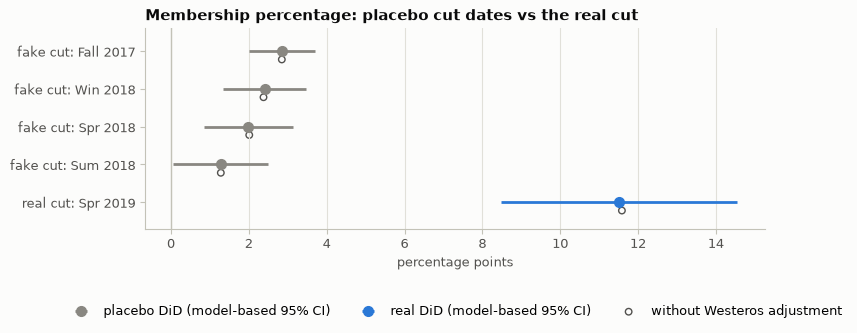

In [138]:
y = 'member_pct'

rows = []
for k in fake_cuts:
    d = pre_cells.assign(fake_post=pre_cells['treated'] * pre_cells['t'].ge(k).astype(int))
    for adj in (True, False):
        fit = u.fit_wls(d, y, ['fake_post'], westeros_adj=adj)
        rows.append({'cut': f'fake cut: {u.period_label(k)}', 'westeros_adj': adj,
                     **u.coef_table(fit, ['fake_post']).iloc[0]})
placebos[y] = pd.DataFrame(rows)
placebos[y].round(3)

u.plot_placebos(placebos[y], dids[y], y)
plt.show()

**Reading: membership percentage**

* **Event study.** All three post-cut seasons are far above the band: +6.3, +12.3 and +13.2 pp, against −0.93 ± 3.82. There is a pre-trend: the gap rises from −3.6 pp in winter 2017 to ≈ 0 by winter 2018.
* **Placebos.** ≈ +2.4 and +2.0 pp, and their model CIs exclude 0. This is the 2017 pre-trend showing up.
* **DiD.** +11.5 pp, model CI [+8.5, +14.5]. The post − pre gap is +11.5, far outside the ±2.4 band, and about 5× the placebos. Without the Westeros adjustment it is +11.6 pp.
* **Caution.** Panem's own member share fell from 18.2% to 11.1% between winter and summer 2019 with no price change (see 3.1). Part of the post-cut gap is panem's drop, not the cut regions' rise.

## 4. All three metrics side by side

In [139]:
rows = {}
for y, meta in u.METRICS.items():
    d, b, p = dids[y], bands[y][True], points[y][True]
    pl = placebos[y][placebos[y]['westeros_adj']]
    rows[meta['label']] = {
        'DiD (with Westeros adj.)': round(d.loc[True, 'estimate'], 3),
        'model 95% CI': f"[{d.loc[True, 'ci_low']:+.3f}, {d.loc[True, 'ci_high']:+.3f}]",
        'post − pre avg gap': round(b['post_avg_gap'], 3),
        'historical band (avg)': f"±{b['half_width_avg']:.3f}",
        'post seasons outside band': f"{p.loc[p['post'], 'vs_band'].ne('inside').sum()} of {int(p['post'].sum())}",
        'placebo DiDs (Win 2018, Spr 2018)': ', '.join(f"{v:+.3f}" for v in pl['estimate']),
        'DiD without Westeros adj.': round(d.loc[False, 'estimate'], 3),
    }
pd.DataFrame(rows).T

,DiD (with Westeros adj.),model 95% CI,post − pre avg gap,historical band (avg),post seasons outside band,"placebo DiDs (Win 2018, Spr 2018)",DiD without Westeros adj.
Revenue per customer,0.365,"[+0.067, +0.663]",0.367,±0.232,2 of 3,"+0.193, +0.138, +0.079, -0.064",0.374
Log revenue per customer,0.015,"[-0.156, +0.186]",0.016,±0.307,0 of 3,"+0.059, +0.026, +0.003, -0.224",0.021
Membership percentage,11.509,"[+8.474, +14.544]",11.522,±2.418,3 of 3,"+2.848, +2.409, +1.991, +1.281",11.585
